# A/B test — independent check in Python
The main analysis lives in `excel/ab_test_analysis.xlsx`. This notebook re-runs the statistics with
standard libraries to confirm the Excel results, then goes two steps further than the workbook:
**statistical power** (was the control group big enough?) and **segment-level confidence intervals**
(which segment differences are real?). It also writes the Tableau extract and README charts.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import (confint_proportions_2indep, proportion_effectsize,
                                          proportions_ztest)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CHARTS, TABLEAU = ROOT / "charts", ROOT / "tableau"
CHARTS.mkdir(exist_ok=True); TABLEAU.mkdir(exist_ok=True)

BLUE, GRAY, ORANGE = "#2a78d6", "#b8b6ae", "#eb6834"
INK, INK2, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": "#d6d5cf",
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#ecebe7",
    "axes.axisbelow": True, "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "figure.dpi": 110,
})

df = pd.read_csv(ROOT / "data/ab_test_clean.csv")
df.head()

,user_id,test_group,converted,total_ads,ads_bucket,most_ads_day,most_ads_hour
0,1069124,ad,0,130,100+,Monday,20
1,1119715,ad,0,93,50-99,Tuesday,22
2,1144181,ad,0,21,10-24,Tuesday,18
3,1435133,ad,0,355,100+,Tuesday,10
4,1015700,ad,0,276,100+,Friday,14


## 1. Re-run the core test

In [2]:
g = df.groupby("test_group")["converted"].agg(users="count", conversions="sum")
g["rate"] = g["conversions"] / g["users"]
display(g)

count = g.loc[["ad", "psa"], "conversions"].values
nobs = g.loc[["ad", "psa"], "users"].values
z, p = proportions_ztest(count, nobs)
lo, hi = confint_proportions_2indep(count[0], nobs[0], count[1], nobs[1], method="wald")
chi2, chi_p, _, _ = stats.chi2_contingency([[count[0], count[1]], [nobs[0] - count[0], nobs[1] - count[1]]],
                                           correction=False)
lift = g.loc["ad", "rate"] - g.loc["psa", "rate"]
print(f"Lift: {lift*100:+.3f} pp ({lift / g.loc['psa','rate']:+.1%} relative)")
print(f"z = {z:.2f}, p = {p:.3g}   |   95% CI for lift: [{lo*100:.3f}, {hi*100:.3f}] pp")
print(f"chi-square = {chi2:.2f} (= z² {z**2:.2f}), p = {chi_p:.3g}")
print(f"Extra conversions from ads: {lift * nobs[0]:,.0f}")

,users,conversions,rate
test_group,,,
ad,564577,14423,0.025547
psa,23524,420,0.017854


Lift: +0.769 pp (+43.1% relative)
z = 7.37, p = 1.71e-13   |   95% CI for lift: [0.595, 0.943] pp
chi-square = 54.32 (= z² 54.32), p = 1.71e-13
Extra conversions from ads: 4,343


These match the Excel workbook exactly (z = 7.37, p = 1.7 × 10⁻¹³, CI +0.60 to +0.94 pp).

## 2. Was the control group big enough? (power analysis)
The PSA group is only 4% of users. Power = the chance the test detects a real effect of a given size.

In [3]:
power_calc = NormalIndPower()
ratio = nobs[1] / nobs[0]
base = g.loc["psa", "rate"]
observed_es = proportion_effectsize(g.loc["ad", "rate"], base)
achieved = power_calc.power(effect_size=observed_es, nobs1=nobs[0], alpha=0.05, ratio=ratio)

rows = []
for rel in [0.05, 0.10, 0.20, 0.30, 0.43]:
    es = proportion_effectsize(base * (1 + rel), base)
    rows.append({"relative lift": f"{rel:.0%}",
                 "power with this design": power_calc.power(effect_size=es, nobs1=nobs[0], alpha=0.05, ratio=ratio)})
power_table = pd.DataFrame(rows)
print(f"Power to detect the observed +43% lift: {achieved:.1%}")
power_table.style.format({"power with this design": "{:.0%}"})

Power to detect the observed +43% lift: 100.0%


,relative lift,power with this design
0,5%,17%
1,10%,51%
2,20%,97%
3,30%,100%
4,43%,100%


In [4]:
# smallest relative lift detectable with 80% power, given this design
mde_es = power_calc.solve_power(nobs1=nobs[0], alpha=0.05, power=0.80, ratio=ratio)
target = lambda r: proportion_effectsize(base * (1 + r), base) - mde_es
from scipy.optimize import brentq
mde = brentq(target, 0.001, 2)
# the same minimum detectable effect with a 50/50 split of the same total users
n_half = nobs.sum() / 2
mde_es_even = power_calc.solve_power(nobs1=n_half, alpha=0.05, power=0.80, ratio=1)
mde_even = brentq(lambda r: proportion_effectsize(base * (1 + r), base) - mde_es_even, 0.001, 2)
print(f"Minimum detectable lift (80% power): {mde:.1%} with the 96/4 split vs {mde_even:.1%} with a 50/50 split")

Minimum detectable lift (80% power): 14.3% with the 96/4 split vs 5.5% with a 50/50 split


**Takeaway:** the test was powerful enough for the effect it found (~100%), but the 96/4 split means it could only
reliably detect lifts above ~14%. A 50/50 split of the same traffic could detect ~6% lifts — worth knowing
for the next, subtler test. The trade-off: every user in the control group is a user not seeing the ad.

## 3. Segment lifts with confidence intervals
The Excel Segments sheet shows point estimates. Adding 95% intervals shows which segment differences are real.

In [5]:
def seg_ci(col, order):
    out = []
    for k in order:
        s = df[df[col] == k]
        a = s[s["test_group"] == "ad"]["converted"]; b = s[s["test_group"] == "psa"]["converted"]
        l, h = confint_proportions_2indep(a.sum(), len(a), b.sum(), len(b), method="wald")
        out.append({"segment": k, "ad_rate": a.mean(), "psa_rate": b.mean(), "lift_pp": (a.mean() - b.mean()) * 100,
                    "ci_low_pp": l * 100, "ci_high_pp": h * 100, "psa_conversions": int(b.sum())})
    return pd.DataFrame(out)

buckets = seg_ci("ads_bucket", ["1-9", "10-24", "25-49", "50-99", "100+"])
days = seg_ci("most_ads_day", ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
display(buckets.round(3)); display(days.round(3))

,segment,ad_rate,psa_rate,lift_pp,ci_low_pp,ci_high_pp,psa_conversions
0,1-9,0.003,0.004,-0.068,-0.185,0.050,41
1,10-24,0.009,0.010,-0.046,-0.298,0.206,61
2,25-49,0.033,0.025,0.836,0.311,1.362,90
3,50-99,0.114,0.055,5.820,4.756,6.884,106
4,100+,0.172,0.118,5.344,3.310,7.378,122


,segment,ad_rate,psa_rate,lift_pp,ci_low_pp,ci_high_pp,psa_conversions
0,Monday,0.033,0.023,1.068,0.562,1.575,79
1,Tuesday,0.030,0.014,1.599,1.148,2.050,42
2,Wednesday,0.025,0.016,0.960,0.532,1.387,55
3,Thursday,0.022,0.020,0.141,-0.312,0.594,79
4,Friday,0.022,0.016,0.616,0.202,1.030,62
5,Saturday,0.021,0.014,0.731,0.289,1.173,40
6,Sunday,0.025,0.021,0.402,-0.112,0.917,63


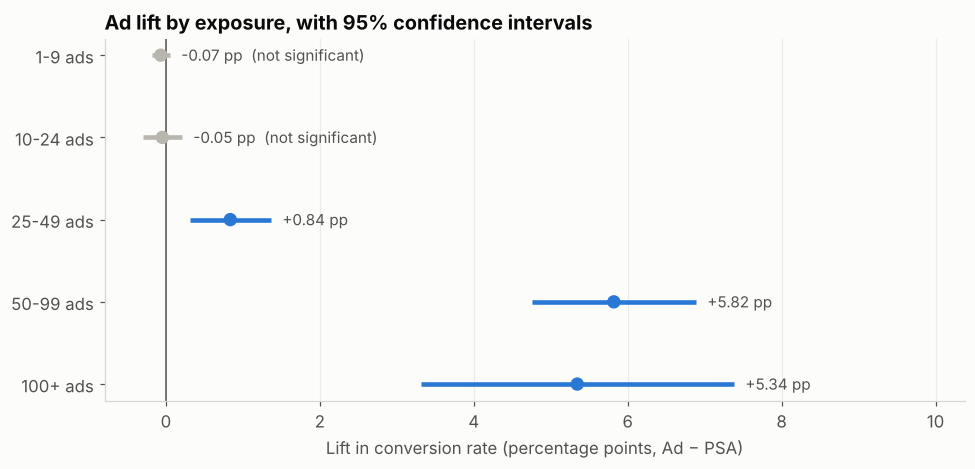

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.4))
y = np.arange(len(buckets))
sig = buckets["ci_low_pp"] > 0
ax.hlines(y, buckets["ci_low_pp"], buckets["ci_high_pp"], color=[BLUE if s else GRAY for s in sig], lw=3)
ax.scatter(buckets["lift_pp"], y, color=[BLUE if s else GRAY for s in sig], s=60, zorder=3)
ax.axvline(0, color=INK2, lw=1)
for yi, (v, s) in enumerate(zip(buckets["lift_pp"], sig)):
    ax.text(buckets["ci_high_pp"].iloc[yi] + 0.15, yi, f"{v:+.2f} pp" + ("" if s else "  (not significant)"),
            va="center", fontsize=10, color=INK2)
ax.set_yticks(y, [f"{b} ads" for b in buckets["segment"]])
ax.invert_yaxis()
ax.set_title("Ad lift by exposure, with 95% confidence intervals")
ax.set_xlabel("Lift in conversion rate (percentage points, Ad − PSA)")
ax.set_xlim(buckets["ci_low_pp"].min() - 0.5, buckets["ci_high_pp"].max() + 3)
ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(CHARTS / "02_lift_by_exposure.png", dpi=160); plt.show()

**Below ~25 ads, the ad performs no better than a PSA** — the intervals straddle zero. The lift only appears once
users see 25+ ads. Because both groups saw the same number of slots, this within-bucket comparison is fair, but
exposure itself wasn't randomised (heavier users see more ads), so treat it as a strong hint for frequency
capping tests, not proof.

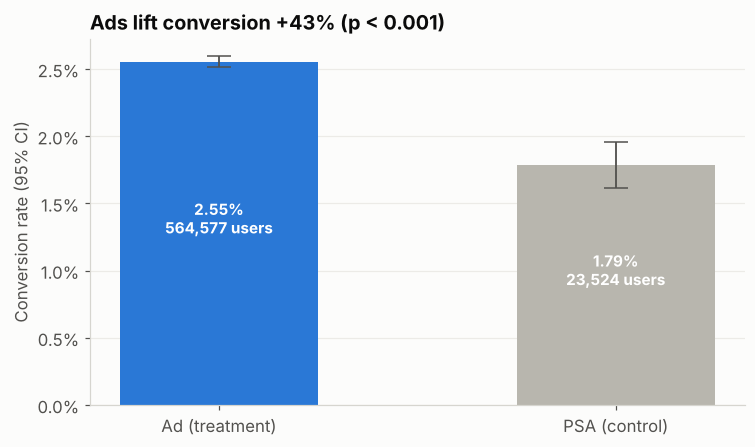

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.2))
rates = g.loc[["ad", "psa"], "rate"] * 100
ci_half = 1.96 * np.sqrt(g.loc[["ad", "psa"], "rate"] * (1 - g.loc[["ad", "psa"], "rate"]) / g.loc[["ad", "psa"], "users"]) * 100
bars = ax.bar(["Ad (treatment)", "PSA (control)"], rates, color=[BLUE, GRAY], width=0.5,
              yerr=ci_half, capsize=8, error_kw={"ecolor": INK2, "lw": 1.2})
for b, r, n in zip(bars, rates, g.loc[["ad", "psa"], "users"]):
    ax.text(b.get_x() + b.get_width() / 2, r / 2, f"{r:.2f}%\n{n:,} users", ha="center", color="white",
            fontsize=10, fontweight="bold")
ax.set_title(f"Ads lift conversion {lift / g.loc['psa','rate']:+.0%} (p < 0.001)")
ax.set_ylabel("Conversion rate (95% CI)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=1))
ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(CHARTS / "01_conversion_by_group.png", dpi=160); plt.show()

## 4. Tableau extract
Tableau Public works best with a compact file, so aggregate to one row per group × day × hour × exposure bucket.

In [8]:
extract = (df.groupby(["test_group", "most_ads_day", "most_ads_hour", "ads_bucket"])
             .agg(users=("user_id", "count"), conversions=("converted", "sum"), total_ads=("total_ads", "sum"))
             .reset_index())
extract["test_group"] = extract["test_group"].map({"ad": "Ad", "psa": "PSA"})
extract.to_csv(TABLEAU / "ab_test_tableau_extract.csv", index=False)
assert extract["users"].sum() == len(df) and extract["conversions"].sum() == df["converted"].sum()
print(f"{len(extract):,} rows, totals reconcile with the raw data")

1,616 rows, totals reconcile with the raw data
